A SCORE MEANS NOTHING UNTIL WE KNOW WHAT AN EASY MODEL SCORES FOR THE DATSET. BASELINES PROVIDES US VALUES TO COMPARE AGAINST OUR MODEL.

In [2]:
import os
print(os.listdir("data/processed") if os.path.exists("data/processed") else "no folder yet")

['X_test.csv', 'X_train.csv', 'X_val.csv', 'y_test.csv', 'y_train.csv', 'y_val.csv']


In [3]:
#LOADING THE REQUIRED LIBRARIES AND SAVED SPLITS FROM PREPROCESSING 
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
import joblib

X_train = pd.read_csv("data/processed/X_train.csv")
X_val   = pd.read_csv("data/processed/X_val.csv")
X_test  = pd.read_csv("data/processed/X_test.csv")
y_train = pd.read_csv("data/processed/y_train.csv").squeeze()
y_val   = pd.read_csv("data/processed/y_val.csv").squeeze()
y_test  = pd.read_csv("data/processed/y_test.csv").squeeze()

print(X_train.shape, X_val.shape, X_test.shape)

(170235, 30) (56745, 30) (56746, 30)


In [4]:
#BUILDING THE <DUMB> MODEL
#THIS MODEL WILL IGNORE THE DATSET AND WILL ALWAYS ANSWER NORMALLY. IT WILL BE HIGHLY ACCURATE AND ACTS AS AN ACCURACY TRAP THAT'S WHY WE USE OTHER METRICS.
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
pred = dummy.predict(X_val)

print("Accuracy:", accuracy_score(y_val, pred))
print("Frauds caught:", ((pred == 1) & (y_val == 1)).sum())
print("Total frauds in validation:", (y_val == 1).sum())

Accuracy: 0.9983434663847035
Frauds caught: 0
Total frauds in validation: 94


In [5]:
#DESIGNING THE SCORING FUNCTION: IT HELPS US TO MAKE SURE ALL THE MODELS ARE EVALUATED ON THE SAME METRICS AND WE CAN COMPARE THEM FAIRLY.
#PR-AUC: IS OUR MAIN METRIC. IT REWARDS THE MODEL THAT DETECTS THE FRAUDS NEAR THE TOP AND DOESN'T FLAG TOO MANY NORMAL TRANSACTIONS AS FRAUDS. IT'S A GOOD METRIC FOR IMBALANCED DATASETS.
#ROC-AUC: IS OUR SECONDARY METRIC. IT TEMDS TO LOOK HIGH ON IMBALANCED DATSETS.
from sklearn.metrics import average_precision_score, roc_auc_score

def report(name, y_true, scores):
    ap = average_precision_score(y_true, scores)
    roc = roc_auc_score(y_true, scores)
    print(f"{name:25s} PR-AUC = {ap:.4f}   ROC-AUC = {roc:.4f}")

In [6]:
#A SUPERVISED BASELINE USING LOGISTIC REGRESSION ( IT LEARNS A BOUNDARY BETWEEN FRAUDS AND NORMAL TRANSACTIONS)
#PREDICT_PROB(...) RETURNS THE PROBABILITY OF EACH TRANSACTION TO BE FRAUD WHICH IS OUR SCORE. WE USE THE SCORE TO COMPUTE THE PR-AUC AND ROC-AUC.
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression(class_weight="balanced", max_iter=1000)
lr.fit(X_train, y_train)
lr_val = lr.predict_proba(X_val)[:, 1]
report("Logistic Regression", y_val, lr_val)


Logistic Regression       PR-AUC = 0.6926   ROC-AUC = 0.9712


In [8]:
#BUILDING AN ANOMALY MODEL USING ISOLATION FOREST( IT BUILD MANY RANDOM QUESTION TREES AND WILL COUNT HOW MANY TREES IT TAKES TO ISOLATE EACH TRANSACTION)
#THE FRAUDS WILL BE ISOLATED QUICKLY AND WILL HAVE A HIGHER SCORE THAN NORMAL TRANSACTIONS.
from sklearn.ensemble import IsolationForest
import os

fraud_rate = y_train.mean()
print("Fraud rate in training data:", fraud_rate)

iso = IsolationForest(n_estimators=200,                  #NO. OF QUESTION TREES
                      contamination=fraud_rate,          #EXPECTED FRAUD RATE IN THE DATASET
                      random_state=42,
                      n_jobs=-1)
iso.fit(X_train)

os.makedirs("models", exist_ok=True)
joblib.dump(iso, "models/isolation_forest.joblib")

Fraud rate in training data: 0.0016682820806532147


['models/isolation_forest.joblib']

In [9]:
#SCORING THE VALIDATION DATA
iso_val = -iso.score_samples(X_val)
report("Isolation Forest", y_val, iso_val)

Isolation Forest          PR-AUC = 0.0873   ROC-AUC = 0.9368


THE ISOLATION FOREST SCORES LOW HERE THAN LOGISTIC REGRESSION BECAUSE IN LOGISTIC REGRESSION THE MODEL IS TOLD WHICH ROWS ARE FRAUD BUT THE ISOLATION FOREST HAS TO GUESS WHAT "UNSUAL" MEANS

USING LOCAL OUTLIER FACTOR AND SVM TO TEACH THE MODELS WHAT NORMAL MEANS FROM NORMAL-ONLY DATA

In [10]:
#Y_TRAIN==0 KEEPS ONLY NORMAL TRANSACTIONS
X_normal = X_train[y_train == 0]
print("Normal training rows:", X_normal.shape)


Normal training rows: (169951, 30)


In [11]:
#USING LOCAL OUTLIER FACTOR(IT COMPARES HOW CRWODED A POINT'S NEIGHBORHOOD IS WITH HOW CROWDED IT'S NEIGHBOR'S NEIGHBORHOOD ARE)
from sklearn.neighbors import LocalOutlierFactor

lof = LocalOutlierFactor(n_neighbors=20, novelty=True, n_jobs=-1)
lof.fit(X_normal.sample(30000, random_state=42))

lof_val = -lof.score_samples(X_val)
report("Local Outlier Factor", y_val, lof_val)


c:\Users\Sakshi\OneDrive\Desktop\CREDIT CARD FRAUD DETECTION\venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LocalOutlierFactor was fitted with feature names
  warnings.warn(


Local Outlier Factor      PR-AUC = 0.4058   ROC-AUC = 0.9073


In [12]:
#USING ONE CLASS SVM(IT DRAWS A FLEXIBLE BOUNDARY AROUND THE NORMAL DATA. POINTS FAR OUTSIDE THE BOUNDARY ARE ANOMALIES)
from sklearn.svm import OneClassSVM

ocsvm = OneClassSVM(kernel="rbf", gamma="scale", nu=0.01)
ocsvm.fit(X_normal.sample(20000, random_state=42))

oc_val = -ocsvm.decision_function(X_val)
report("One-Class SVM", y_val, oc_val)

One-Class SVM             PR-AUC = 0.1369   ROC-AUC = 0.9327


In [13]:
#MAKING A TABLE OF ALL THE MODELS AND THEIR SCORES. THIS WILL HELP US TO COMPARE THEM FAIRLY.
import pandas as pd
from sklearn.metrics import average_precision_score, roc_auc_score

val_scores = {
    "Logistic Regression": lr_val,
    "Isolation Forest": iso_val,
    "Local Outlier Factor": lof_val,
    "One-Class SVM": oc_val,
}

results = pd.DataFrame({
    name: {"PR-AUC": average_precision_score(y_val, s),
           "ROC-AUC": roc_auc_score(y_val, s)}
    for name, s in val_scores.items()
}).T.round(4).sort_values("PR-AUC", ascending=False)

results

,PR-AUC,ROC-AUC
Logistic Regression,0.6926,0.9712
Local Outlier Factor,0.4058,0.9073
One-Class SVM,0.1369,0.9327
Isolation Forest,0.0873,0.9368


COMPARING THE MODELS AND CHOOSING THE THRESHOLD 

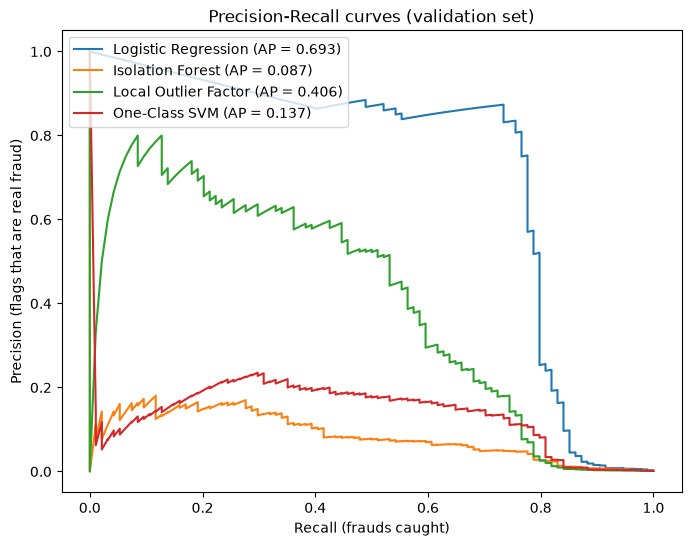

In [15]:
#BUILDING PRECISION RECALL CURVES
from sklearn.metrics import precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt
import os

plt.figure(figsize=(8, 6))
for name, s in val_scores.items():
    p, r, _ = precision_recall_curve(y_val, s)
    ap = average_precision_score(y_val, s)
    plt.plot(r, p, label=f"{name} (AP = {ap:.3f})")

plt.xlabel("Recall (frauds caught)")
plt.ylabel("Precision (flags that are real fraud)")
plt.title("Precision-Recall curves (validation set)")
plt.legend()

os.makedirs("reports/figures", exist_ok=True)
plt.savefig("reports/figures/pr_curves.png", dpi=150, bbox_inches="tight")
plt.show()

In [16]:
#PICNKING A THRESHOLD ON VALIDATION DATA(IT TRIES EVERY POSSIBLE CUTOFF AND KEEPS THE BEST F1 SCORE. F1 IS NEUTRAL DEFAULT)
import numpy as np

def best_threshold(y_true, scores):
    p, r, t = precision_recall_curve(y_true, scores)
    f1 = 2 * p * r / (p + r + 1e-12)
    i = np.argmax(f1[:-1])          # thresholds have one fewer entry
    return t[i], p[i], r[i], f1[i]

thresholds = {}
for name, s in val_scores.items():
    thr, p, r, f1 = best_threshold(y_val, s)
    thresholds[name] = thr
    print(f"{name:22s} threshold={thr:8.4f}  precision={p:.3f}  recall={r:.3f}  F1={f1:.3f}")

Logistic Regression    threshold=  1.0000  precision=0.873  recall=0.734  F1=0.798
Isolation Forest       threshold=  0.6309  precision=0.170  recall=0.277  F1=0.211
Local Outlier Factor   threshold=  2.8947  precision=0.515  recall=0.532  F1=0.524
One-Class SVM          threshold=  1.0540  precision=0.200  recall=0.426  F1=0.272


EVALUATING ON THE TEST DATASET

In [17]:
from sklearn.metrics import confusion_matrix, classification_report

test_scores = {
    "Logistic Regression": lr.predict_proba(X_test)[:, 1],
    "Isolation Forest": -iso.score_samples(X_test),
    "Local Outlier Factor": -lof.score_samples(X_test),
    "One-Class SVM": -ocsvm.decision_function(X_test),
}

rows = []
for name, s in test_scores.items():
    y_pred = (s >= thresholds[name]).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    rows.append({
        "Model": name,
        "PR-AUC": round(average_precision_score(y_test, s), 4),
        "Precision": round(tp / (tp + fp + 1e-12), 3),
        "Recall": round(tp / (tp + fn + 1e-12), 3),
        "Frauds caught": tp,
        "Frauds missed": fn,
        "False alarms": fp,
    })

final = pd.DataFrame(rows).set_index("Model").sort_values("PR-AUC", ascending=False)
final

c:\Users\Sakshi\OneDrive\Desktop\CREDIT CARD FRAUD DETECTION\venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LocalOutlierFactor was fitted with feature names
  warnings.warn(


,PR-AUC,Precision,Recall,Frauds caught,Frauds missed,False alarms
Model,,,,,,
Logistic Regression,0.7306,0.887,0.747,71,24,9
Local Outlier Factor,0.4443,0.527,0.516,49,46,44
One-Class SVM,0.2067,0.282,0.526,50,45,127
Isolation Forest,0.1381,0.197,0.316,30,65,122


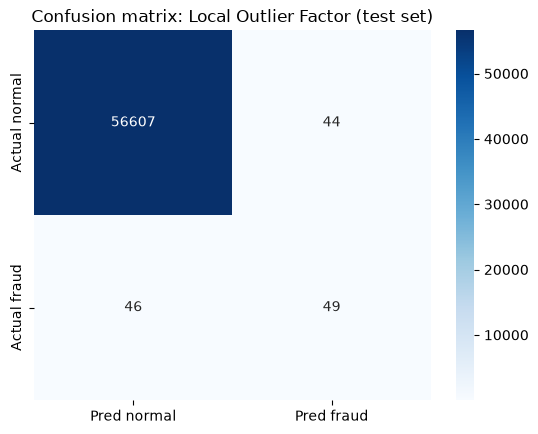

In [ ]:
#CONFUDION MATRIX FOR THE BEST ANOMALY DETECTOR (LOGISTIC REGRESSION) ON TEST DATA
import seaborn as sns

best = "Local Outlier Factor"
y_pred = (test_scores[best] >= thresholds[best]).astype(int)
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Pred normal", "Pred fraud"],
            yticklabels=["Actual normal", "Actual fraud"])
plt.title(f"Confusion matrix: {best} (test set)")
plt.savefig("reports/figures/confusion_matrix_lof.png", dpi=150, bbox_inches="tight")
plt.show()